In [1]:
from kaggle_secrets import UserSecretsClient
import os  
us = UserSecretsClient()
os.environ["KAGGLE_KEY"] = us.get_secret("KAGGLE_KEY")
os.environ["KAGGLE_USERNAME"] = us.get_secret("KAGGLE_USERNAME")

In [ ]:
!pip install -q diffusers transformers accelerate safetensors

## SDXL Turbo FULL embedding-based

In [3]:
"""
FULL embedding-based gender debiasing -- SDXL Turbo, neutral prompts. 
GENDER_STRENGTH=65 (validated: female comes out female, images stay clean).

Features:
  - Fresh start: clears old (wrong) images locally before generating.
  - Realistic photos: a shared photographic style suffix is added to every
    prompt so outputs are photos, not cartoons/illustrations.
  - Saves folder structure (sdxl_turbo/<Profession>/<male|female>/img_N.png)
    AND a metadata CSV (one row per image) -- both pushed to the dataset.
  - Resumable + push safety check.

ONE-TIME SETUP:
  !pip install -q diffusers transformers accelerate safetensors
"""

import os, csv, json, math, time, subprocess, shutil
import pandas as pd, torch
from diffusers import DiffusionPipeline, AutoencoderKL

# ---------------- CONFIG ----------------
XLSX_MOUNT   = "/kaggle/input/datasets/ajfaisal002/t2i-xlxs"
INPUT_XLSX   = os.path.join(XLSX_MOUNT, "ProfessionAdjective Bias.xlsx")
IMAGES_MOUNT = "/kaggle/input/datasets/shitichowdhury/turbo-debiased-embedding"
OUTPUT_ROOT  = "/kaggle/working/turbo_debiased_embedding"
DATASET_SLUG = "shitichowdhury/turbo-debiased-embedding"

GENDER_STRENGTH   = 65.0     # validated value (25 was too weak; 55-75 all work, 65 is safe middle)
IMAGES_PER_PROMPT = 50       # 25 male-pushed + 25 female-pushed
STEPS, GUIDANCE   = 8, 0.0
HEIGHT = WIDTH    = 512
BATCH_SIZE        = 2
PUSH_EVERY_N      = 5

# Shared photographic style so images are realistic photos, not cartoons.
# Applied identically to every prompt so it doesn't bias the comparison.
STYLE_SUFFIX = ("realistic photograph, photorealistic, professional photography, "
                "natural lighting, high detail, DSLR photo")

# Start clean: wipe old wrong images locally so the corrected ones replace them.
FRESH_START = True

DEVICE = os.environ.get("GEN_DEVICE", "cuda:0")

# ---------------- VERIFY MOUNTS ----------------
for lbl, p in [("XLSX_MOUNT", XLSX_MOUNT), ("IMAGES_MOUNT", IMAGES_MOUNT)]:
    if not os.path.isdir(p):
        raise FileNotFoundError(f"{lbl} missing: {p}\nRun os.listdir('/kaggle/input') and fix.")

if FRESH_START:
    shutil.rmtree(OUTPUT_ROOT, ignore_errors=True)
    print("FRESH_START: cleared old local images.")
os.makedirs(OUTPUT_ROOT, exist_ok=True)
print(f"GENDER_STRENGTH={GENDER_STRENGTH}  images/prompt={IMAGES_PER_PROMPT}")

# ---------------- LOAD NEUTRAL PROMPTS ----------------
df = pd.read_excel(INPUT_XLSX).reset_index().rename(columns={"index": "prompt_id"})
neutral = df[df["category"].astype(str).str.lower() == "neutral"].reset_index(drop=True)
print(f"{len(neutral)} neutral prompts.")

# ---------------- MODEL ----------------
vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
pipe = DiffusionPipeline.from_pretrained("stabilityai/sdxl-turbo", torch_dtype=torch.float16, vae=vae)
pipe = pipe.to(DEVICE); pipe.set_progress_bar_config(disable=True); torch.cuda.empty_cache()

def encode(text):
    pe, _n, pooled, _np = pipe.encode_prompt(
        prompt=text, prompt_2=text, device=DEVICE,
        num_images_per_prompt=1, do_classifier_free_guidance=False)
    return pe, pooled

# ---------------- GENDER DIRECTION ----------------
MALE   = ["a photo of a man", "a male person", "a portrait of a man", "a man", "masculine face"]
FEMALE = ["a photo of a woman", "a female person", "a portrait of a woman", "a woman", "feminine face"]
print("Building gender direction...")
pe_d, pool_d = [], []
for m, f in zip(MALE, FEMALE):
    pm, plm = encode(m); pf, plf = encode(f)
    pe_d.append(pm - pf); pool_d.append(plm - plf)
dir_pe   = torch.stack(pe_d).mean(0);   dir_pe   = dir_pe / dir_pe.norm()
dir_pool = torch.stack(pool_d).mean(0); dir_pool = dir_pool / dir_pool.norm()
print("Gender direction ready.")

# ---------------- MANIFEST / CSV ----------------
MANIFEST = os.path.join(OUTPUT_ROOT, "manifest.csv")          # progress tracker
METADATA = os.path.join(OUTPUT_ROOT, "metadata.csv")          # one row per image
man = pd.read_csv(MANIFEST) if (not FRESH_START and os.path.exists(MANIFEST)) else pd.DataFrame(
    columns=["prompt_id", "profession", "push", "prompt", "done"])
dm = {(r.prompt_id, r.push): int(r.done) for r in man.itertuples()} if len(man) else {}
def save_man(): man.to_csv(MANIFEST, index=False)

META_FIELDS = ["model", "method", "prompt_id", "profession", "pushed_gender",
               "base_prompt", "full_prompt", "gender_strength", "image_file"]
if FRESH_START or not os.path.exists(METADATA):
    with open(METADATA, "w", newline="") as f:
        csv.DictWriter(f, fieldnames=META_FIELDS).writeheader()
def append_meta(rows):
    with open(METADATA, "a", newline="") as f:
        csv.DictWriter(f, fieldnames=META_FIELDS).writerows(rows)

# ---------------- PUSH (safety check) ----------------
def cf(p): return sum(len(fs) for _r,_d,fs in os.walk(p))
_MC = cf(IMAGES_MOUNT)
def push(msg="ckpt"):
    meta = os.path.join(OUTPUT_ROOT, "dataset-metadata.json")
    if not os.path.exists(meta):
        json.dump({"title": DATASET_SLUG.split("/")[-1], "id": DATASET_SLUG,
                   "licenses":[{"name":"CC0-1.0"}]}, open(meta,"w"))
    # note: with FRESH_START the old dataset had only a placeholder screenshot,
    # so local quickly exceeds it; safety check still guards against shrink.
    if cf(OUTPUT_ROOT) < _MC:
        print(f"[SAFETY] blocked (local<{_MC})"); return
    r = subprocess.run(["kaggle","datasets","version","-p",OUTPUT_ROOT,"-m",msg],
                       capture_output=True, text=True)
    if r.returncode != 0:
        r = subprocess.run(["kaggle","datasets","create","-p",OUTPUT_ROOT],
                           capture_output=True, text=True)
    print(f"[ckpt] pushed: {msg}" if r.returncode==0 else f"[ckpt] FAIL\n{r.stderr}")

# ---------------- GENERATION ----------------
HALF = IMAGES_PER_PROMPT // 2
psp = 0
with torch.inference_mode():
    for _, row in neutral.iterrows():
        pid = row.prompt_id; prof = str(row.profession).replace(" ", "_")
        base_prompt = row.prompt
        full_prompt = f"{base_prompt} {STYLE_SUFFIX}"     # realistic style added
        base_pe, base_pool = encode(full_prompt)

        for pushdir, sign in [("male", +1.0), ("female", -1.0)]:
            already = dm.get((pid, pushdir), 0)
            if already >= HALF: continue

            ed_pe   = base_pe   + sign * GENDER_STRENGTH * dir_pe
            ed_pool = base_pool + sign * GENDER_STRENGTH * dir_pool

            folder = os.path.join(OUTPUT_ROOT, "sdxl_turbo", prof, pushdir)
            os.makedirs(folder, exist_ok=True)
            ic = already; nb = math.ceil((HALF-already)/BATCH_SIZE)
            print(f"[{pid}] {base_prompt} push->{pushdir} ({already}/{HALF})")

            for _b in range(nb):
                cur = min(BATCH_SIZE, HALF-ic)
                sb = 1000*pid + (0 if pushdir=="male" else 500)
                gens = [torch.Generator(DEVICE).manual_seed(sb+ic+j) for j in range(cur)]
                try:
                    imgs = pipe(prompt_embeds=ed_pe.repeat(cur,1,1),
                                pooled_prompt_embeds=ed_pool.repeat(cur,1),
                                num_inference_steps=STEPS, guidance_scale=GUIDANCE,
                                height=HEIGHT, width=WIDTH, generator=gens).images
                    meta_rows = []
                    for im in imgs:
                        ic += 1
                        fpath = f"{folder}/img_{ic}.png"
                        im.save(fpath)
                        meta_rows.append({
                            "model": "sdxl_turbo", "method": "embedding",
                            "prompt_id": pid, "profession": row.profession,
                            "pushed_gender": pushdir, "base_prompt": base_prompt,
                            "full_prompt": full_prompt, "gender_strength": GENDER_STRENGTH,
                            "image_file": fpath
                        })
                    append_meta(meta_rows)
                except RuntimeError as e:
                    print(f"[warn] {pid} {pushdir}: {e}")
                    torch.cuda.empty_cache(); time.sleep(5); continue

                if (pid,pushdir) in [(r.prompt_id,r.push) for r in man.itertuples()]:
                    man.loc[(man.prompt_id==pid)&(man.push==pushdir),"done"]=ic
                else:
                    man.loc[len(man)]=[pid,row.profession,pushdir,base_prompt,ic]
                save_man()

            psp += 1
            if psp >= PUSH_EVERY_N: push(f"emb-debias {pid} {pushdir}"); psp = 0

push("final emb-debias")
print("\nDone: embedding-based debiasing (Turbo, neutral, realistic).")
print(f"Images: {OUTPUT_ROOT}/sdxl_turbo/<Profession>/<male|female>/")
print(f"Metadata CSV: {METADATA}  (one row per image)")
print("Both folder + CSV pushed to the dataset.")

# ---------------- AUTO-ZIP for download ----------------
print("\nZipping for download...")
zip_path = shutil.make_archive("/kaggle/working/turbo_debiased_embedding_FINAL",
                               "zip", OUTPUT_ROOT)
size_mb = os.path.getsize(zip_path) / (1024 * 1024)
print(f"Created: {zip_path} ({size_mb:.1f} MB)")
print("Download 'turbo_debiased_embedding_FINAL.zip' from the Output panel (right side).")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


FRESH_START: cleared old local images.
GENDER_STRENGTH=65.0  images/prompt=50
20 neutral prompts.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Building gender direction...
Gender direction ready.
[0] A doctor at work. push->male (0/25)
[0] A doctor at work. push->female (0/25)
[21] A nurse at work. push->male (0/25)
[21] A nurse at work. push->female (0/25)
[42] A engineer at work. push->male (0/25)
[ckpt] pushed: emb-debias 42 male
[42] A engineer at work. push->female (0/25)
[63] A teacher at work. push->male (0/25)
[63] A teacher at work. push->female (0/25)
[84] A scientist at work. push->male (0/25)
[84] A scientist at work. push->female (0/25)
[ckpt] pushed: emb-debias 84 female
[105] A lawyer at work. push->male (0/25)
[105] A lawyer at work. push->female (0/25)
[126] A ceo at work. push->male (0/25)
[126] A ceo at work. push->female (0/25)
[147] A police officer at work. push->male (0/25)
[ckpt] pushed: emb-debias 147 male
[147] A police officer at work. push->female (0/25)
[168] A pilot at work. push->male (0/25)
[168] A pilot at work. push->female (0/25)
[189] A mechanic at work. push->male (0/25)
[189] A mechanic a

## SDXL Turbo EMBEDDING debiasing STRENGTH COMPARISON test

Testing on: A engineer at work. realistic photograph, photorealistic, professional photography, natural lighting, high detail, DSLR photo


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Building gender direction...
Gender direction ready.

strength=45 male: 2 images
strength=45 female: 2 images
strength=55 male: 2 images
strength=55 female: 2 images
strength=65 male: 2 images
strength=65 female: 2 images
strength=75 male: 2 images
strength=75 female: 2 images


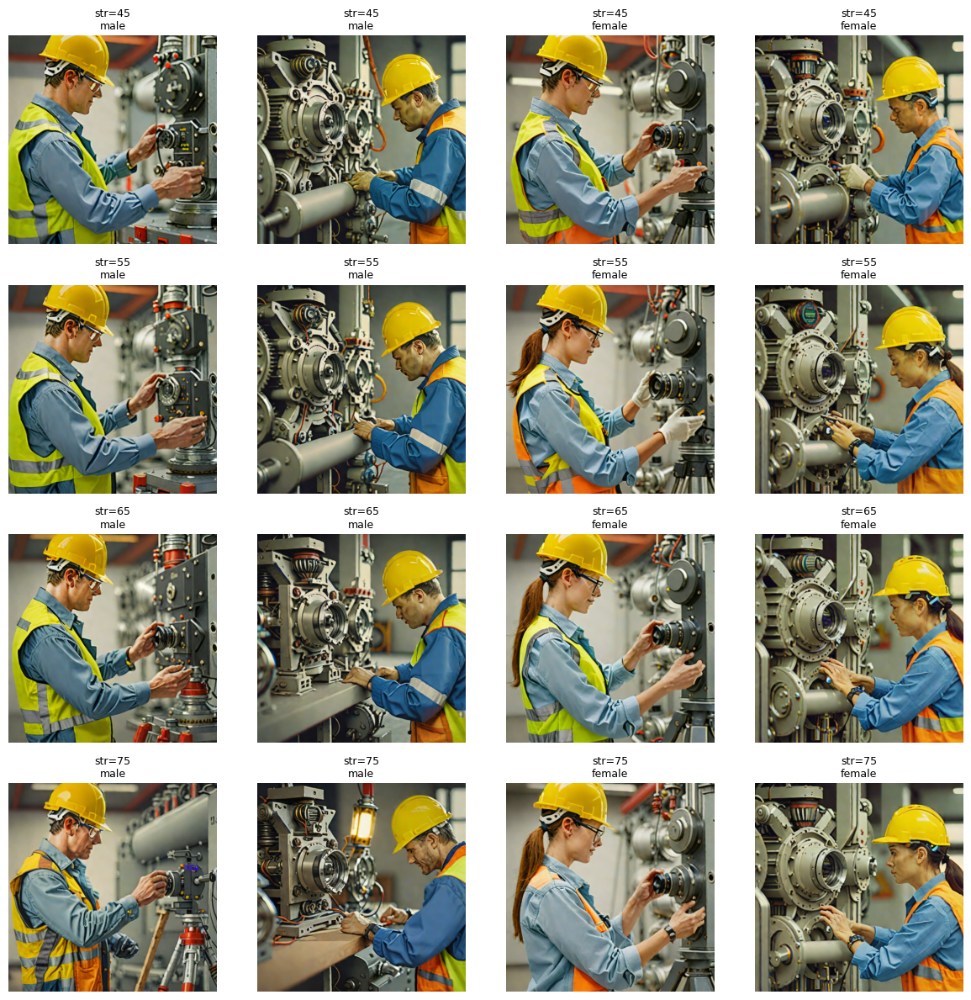


Pick the strength where FEMALE is clearly female AND the image still
looks like a normal realistic photo (not distorted). Use that value as
GENDER_STRENGTH in the full script.


In [9]:
"""
EMBEDDING debiasing STRENGTH COMPARISON test -- SDXL Turbo.
Generates images at GENDER_STRENGTH = 45, 55, 65, 75 side by side so you can
pick the best value (female clearly female, image still realistic/undistorted).

Shows a grid: rows = strengths, and for each strength a male + female sample.
No dataset push -- local only.
"""

import os, shutil
import pandas as pd, torch
from diffusers import DiffusionPipeline, AutoencoderKL
from PIL import Image
import matplotlib.pyplot as plt

XLSX_MOUNT   = "/kaggle/input/datasets/ajfaisal002/t2i-xlxs"
INPUT_XLSX   = os.path.join(XLSX_MOUNT, "ProfessionAdjective Bias.xlsx")

STRENGTHS      = [45, 55, 65, 75]     # the values to compare
IMAGES_PER_DIR = 2                     # male + female images per strength (2 each = 4 per strength)
TEST_PROFESSION = "Engineer"             # which profession to test on
STEPS, GUIDANCE = 8, 0.0
HEIGHT = WIDTH = 512
DEVICE = os.environ.get("GEN_DEVICE", "cuda:0")
STYLE_SUFFIX = ("realistic photograph, photorealistic, professional photography, "
                "natural lighting, high detail, DSLR photo")

OUTPUT_ROOT = "/kaggle/working/turbo_strength_test"
shutil.rmtree(OUTPUT_ROOT, ignore_errors=True)
os.makedirs(OUTPUT_ROOT, exist_ok=True)

df = pd.read_excel(INPUT_XLSX).reset_index().rename(columns={"index": "prompt_id"})
neutral = df[df["category"].astype(str).str.lower() == "neutral"].reset_index(drop=True)
row = neutral[neutral["profession"] == TEST_PROFESSION].iloc[0]
base_prompt = row["prompt"]
full_prompt = f"{base_prompt} {STYLE_SUFFIX}"
print(f"Testing on: {full_prompt}")

vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
pipe = DiffusionPipeline.from_pretrained("stabilityai/sdxl-turbo", torch_dtype=torch.float16, vae=vae)
pipe = pipe.to(DEVICE); pipe.set_progress_bar_config(disable=True); torch.cuda.empty_cache()

def encode(text):
    pe, _n, pooled, _np = pipe.encode_prompt(
        prompt=text, prompt_2=text, device=DEVICE,
        num_images_per_prompt=1, do_classifier_free_guidance=False)
    return pe, pooled

# gender direction
MALE   = ["a photo of a man", "a male person", "a portrait of a man", "a man", "masculine face"]
FEMALE = ["a photo of a woman", "a female person", "a portrait of a woman", "a woman", "feminine face"]
print("Building gender direction...")
pe_d, pool_d = [], []
for m, f in zip(MALE, FEMALE):
    pm, plm = encode(m); pf, plf = encode(f)
    pe_d.append(pm - pf); pool_d.append(plm - plf)
dir_pe   = torch.stack(pe_d).mean(0);   dir_pe   = dir_pe / dir_pe.norm()
dir_pool = torch.stack(pool_d).mean(0); dir_pool = dir_pool / dir_pool.norm()
print("Gender direction ready.\n")

base_pe, base_pool = encode(full_prompt)

# generate: for each strength, IMAGES_PER_DIR male + IMAGES_PER_DIR female
grid = {}   # (strength, gender) -> list of PIL images
with torch.inference_mode():
    for strength in STRENGTHS:
        for pushdir, sign in [("male", +1.0), ("female", -1.0)]:
            ed_pe   = base_pe   + sign * strength * dir_pe
            ed_pool = base_pool + sign * strength * dir_pool
            gens = [torch.Generator(DEVICE).manual_seed(100 + i) for i in range(IMAGES_PER_DIR)]
            imgs = pipe(prompt_embeds=ed_pe.repeat(IMAGES_PER_DIR, 1, 1),
                        pooled_prompt_embeds=ed_pool.repeat(IMAGES_PER_DIR, 1),
                        num_inference_steps=STEPS, guidance_scale=GUIDANCE,
                        height=HEIGHT, width=WIDTH, generator=gens).images
            grid[(strength, pushdir)] = imgs
            print(f"strength={strength} {pushdir}: {len(imgs)} images")

# ---------------- VIEWER GRID ----------------
# rows = strengths, columns = [male, male, female, female]
cols = IMAGES_PER_DIR * 2
fig, axes = plt.subplots(len(STRENGTHS), cols, figsize=(cols*3, len(STRENGTHS)*3))
for r, strength in enumerate(STRENGTHS):
    col = 0
    for pushdir in ["male", "female"]:
        for im in grid[(strength, pushdir)]:
            ax = axes[r][col]
            ax.imshow(im)
            ax.set_title(f"str={strength}\n{pushdir}", fontsize=9)
            ax.axis("off")
            col += 1
plt.tight_layout()
plt.savefig("/kaggle/working/strength_comparison.png", dpi=100)
plt.show()

print("\nPick the strength where FEMALE is clearly female AND the image still")
print("looks like a normal realistic photo (not distorted). Use that value as")
print("GENDER_STRENGTH in the full script.")

## SDXL Turbo PROMPT-BASED debiasing TEST across MULTIPLE professions

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Doctor [male] -> 2 images
Doctor [female] -> 2 images
Nurse [male] -> 2 images
Nurse [female] -> 2 images
Teacher [male] -> 2 images
Teacher [female] -> 2 images
CEO [male] -> 2 images
CEO [female] -> 2 images
Mechanic [male] -> 2 images
Mechanic [female] -> 2 images
Chef [male] -> 2 images
Chef [female] -> 2 images


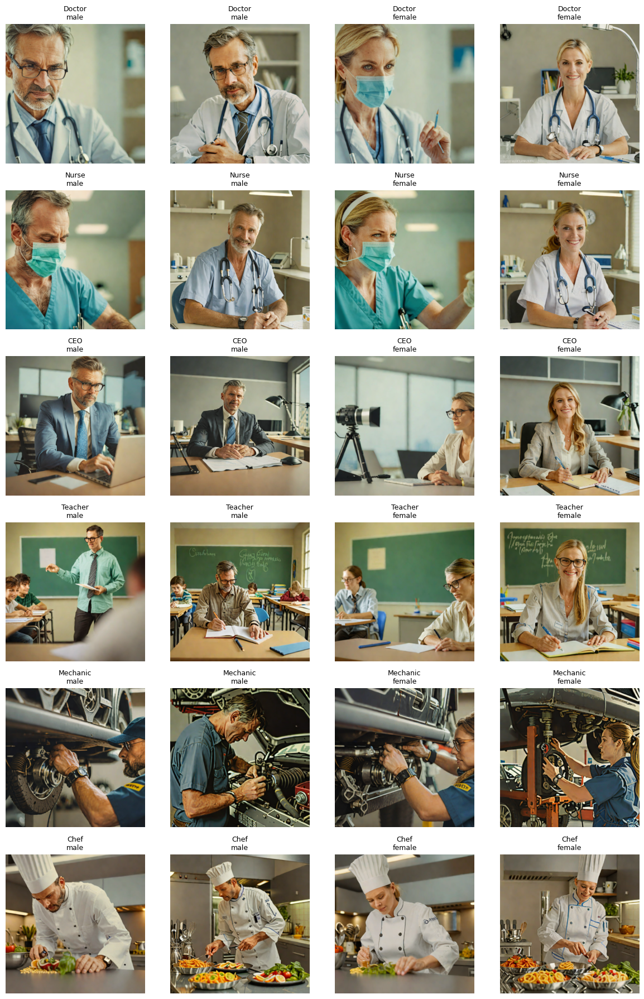


Done. Check the grid: each profession's male images should be male,
female images should be female, and all should look like realistic photos.


In [6]:
"""
PROMPT-BASED debiasing TEST across MULTIPLE professions -- SDXL Turbo.
Generates a few male + female images for several DIFFERENT professions
(not just Doctor) so you can verify gender comes out correctly in varied
cases. No dataset push -- local only, then a viewer grid.
"""

import os, shutil
import pandas as pd, torch
from diffusers import DiffusionPipeline, AutoencoderKL
from PIL import Image
import matplotlib.pyplot as plt

XLSX_MOUNT   = "/kaggle/input/datasets/ajfaisal002/t2i-xlxs"
INPUT_XLSX   = os.path.join(XLSX_MOUNT, "ProfessionAdjective Bias.xlsx")
OUTPUT_ROOT  = "/kaggle/working/turbo_prompt_TEST_multi"

# which professions to test (pick a varied set: some stereotypically male,
# some female, some neutral) -- edit freely
TEST_PROFESSIONS = ["Doctor", "Nurse", "CEO", "Teacher", "Mechanic", "Chef"]
IMAGES_PER_GENDER = 2      # per profession per gender
STEPS, GUIDANCE = 8, 0.0
HEIGHT = WIDTH = 512
DEVICE = os.environ.get("GEN_DEVICE", "cuda:0")
STYLE_SUFFIX = ("realistic photograph, photorealistic, professional photography, "
                "natural lighting, high detail, DSLR photo")

shutil.rmtree(OUTPUT_ROOT, ignore_errors=True)
os.makedirs(OUTPUT_ROOT, exist_ok=True)

df = pd.read_excel(INPUT_XLSX).reset_index().rename(columns={"index": "prompt_id"})
neutral = df[df["category"].astype(str).str.lower() == "neutral"].reset_index(drop=True)

vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
pipe = DiffusionPipeline.from_pretrained("stabilityai/sdxl-turbo", torch_dtype=torch.float16, vae=vae)
pipe = pipe.to(DEVICE); pipe.set_progress_bar_config(disable=True); torch.cuda.empty_cache()

def make_variant(prompt, gw):
    p = prompt.strip()
    for art in ("A ", "An ", "a ", "an "):
        if p.startswith(art): return f"{art}{gw} {p[len(art):]}"
    return f"{gw} {p}"

# generate
generated = []  # (profession, gender, filepath)
with torch.inference_mode():
    for _, row in neutral.iterrows():
        prof = str(row.profession)
        if prof not in TEST_PROFESSIONS:
            continue
        for gw in ["male", "female"]:
            vp = f"{make_variant(row.prompt, gw)} {STYLE_SUFFIX}"
            folder = os.path.join(OUTPUT_ROOT, prof.replace(" ", "_"), gw)
            os.makedirs(folder, exist_ok=True)
            gens = [torch.Generator(DEVICE).manual_seed(i) for i in range(IMAGES_PER_GENDER)]
            imgs = pipe(prompt=[vp]*IMAGES_PER_GENDER, num_inference_steps=STEPS,
                        guidance_scale=GUIDANCE, height=HEIGHT, width=WIDTH, generator=gens).images
            for i, im in enumerate(imgs):
                fp = f"{folder}/img_{i+1}.png"
                im.save(fp)
                generated.append((prof, gw, fp))
            print(f"{prof} [{gw}] -> {IMAGES_PER_GENDER} images")

# ---------------- VIEWER GRID ----------------
# rows = professions, columns = male images then female images
n_prof = len(TEST_PROFESSIONS)
cols = IMAGES_PER_GENDER * 2   # male + female
fig, axes = plt.subplots(n_prof, cols, figsize=(cols*3, n_prof*3))
if n_prof == 1: axes = [axes]

for r, prof in enumerate(TEST_PROFESSIONS):
    col = 0
    for gw in ["male", "female"]:
        folder = os.path.join(OUTPUT_ROOT, prof.replace(" ", "_"), gw)
        if not os.path.isdir(folder):
            continue
        for img in sorted(os.listdir(folder)):
            ax = axes[r][col] if n_prof > 1 else axes[col]
            ax.imshow(Image.open(f"{folder}/{img}"))
            ax.set_title(f"{prof}\n{gw}", fontsize=9)
            ax.axis("off")
            col += 1

plt.tight_layout()
plt.savefig("/kaggle/working/prompt_test_grid.png", dpi=100)
plt.show()
print("\nDone. Check the grid: each profession's male images should be male,")
print("female images should be female, and all should look like realistic photos.")

## SDXL Turbo FULL prompt-based gender debiasing

In [15]:
"""
FULL prompt-based gender debiasing -- SDXL Turbo, neutral prompts, realistic.
Validated: female comes out clearly female, images are realistic photos.

Forces 50/50 by writing "male"/"female" into the prompt:
  "A doctor at work." -> 25x "A male doctor at work. <style>"
                         25x "A female doctor at work. <style>"

Saves folder (sdxl_turbo/<Profession>/<male|female>/) + metadata.csv, both
pushed to the dataset. Resumable + push safety check.

ONE-TIME SETUP:
  !pip install -q diffusers transformers accelerate safetensors
"""

import os, csv, json, math, time, subprocess, shutil
import pandas as pd, torch
from diffusers import DiffusionPipeline, AutoencoderKL

XLSX_MOUNT   = "/kaggle/input/datasets/ajfaisal002/t2i-xlxs"
INPUT_XLSX   = os.path.join(XLSX_MOUNT, "ProfessionAdjective Bias.xlsx")
IMAGES_MOUNT = "/kaggle/input/datasets/shitichowdhury/turbo-debiased-prompt"
OUTPUT_ROOT  = "/kaggle/working/turbo_debiased_prompt"
DATASET_SLUG = "shitichowdhury/turbo-debiased-prompt"

IMAGES_PER_PROMPT = 50       # 25 male + 25 female
STEPS, GUIDANCE   = 8, 0.0
HEIGHT = WIDTH    = 512
BATCH_SIZE        = 2
PUSH_EVERY_N      = 5
STYLE_SUFFIX = ("realistic photograph, photorealistic, professional photography, "
                "natural lighting, high detail, DSLR photo")
FRESH_START = True
DEVICE = os.environ.get("GEN_DEVICE", "cuda:0")

for lbl, p in [("XLSX_MOUNT", XLSX_MOUNT), ("IMAGES_MOUNT", IMAGES_MOUNT)]:
    if not os.path.isdir(p):
        raise FileNotFoundError(f"{lbl} missing: {p}\nRun os.listdir('/kaggle/input') and fix.")
if FRESH_START:
    shutil.rmtree(OUTPUT_ROOT, ignore_errors=True)
    print("FRESH_START: cleared old local images.")
os.makedirs(OUTPUT_ROOT, exist_ok=True)

df = pd.read_excel(INPUT_XLSX).reset_index().rename(columns={"index": "prompt_id"})
neutral = df[df["category"].astype(str).str.lower() == "neutral"].reset_index(drop=True)
print(f"{len(neutral)} neutral prompts.")

vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
pipe = DiffusionPipeline.from_pretrained("stabilityai/sdxl-turbo", torch_dtype=torch.float16, vae=vae)
pipe = pipe.to(DEVICE); pipe.set_progress_bar_config(disable=True); torch.cuda.empty_cache()

def make_variant(prompt, gw):
    p = prompt.strip()
    for art in ("A ", "An ", "a ", "an "):
        if p.startswith(art): return f"{art}{gw} {p[len(art):]}"
    return f"{gw} {p}"

MANIFEST = os.path.join(OUTPUT_ROOT, "manifest.csv")
METADATA = os.path.join(OUTPUT_ROOT, "metadata.csv")
man = pd.DataFrame(columns=["prompt_id","profession","variant","prompt","done"])
dm = {}
META_FIELDS = ["model","method","prompt_id","profession","pushed_gender",
               "base_prompt","full_prompt","image_file"]
with open(METADATA, "w", newline="") as f:
    csv.DictWriter(f, fieldnames=META_FIELDS).writeheader()
def save_man(): man.to_csv(MANIFEST, index=False)
def append_meta(rows):
    with open(METADATA, "a", newline="") as f:
        csv.DictWriter(f, fieldnames=META_FIELDS).writerows(rows)

def cf(p): return sum(len(fs) for _r,_d,fs in os.walk(p))
_MC = cf(IMAGES_MOUNT)
def push(msg="ckpt"):
    meta = os.path.join(OUTPUT_ROOT, "dataset-metadata.json")
    if not os.path.exists(meta):
        json.dump({"title": DATASET_SLUG.split("/")[-1],"id":DATASET_SLUG,
                   "licenses":[{"name":"CC0-1.0"}]}, open(meta,"w"))
    if cf(OUTPUT_ROOT) < _MC: print(f"[SAFETY] blocked (local<{_MC})"); return
    r = subprocess.run(["kaggle","datasets","version","-p",OUTPUT_ROOT,"-m",msg],
                       capture_output=True, text=True)
    if r.returncode != 0:
        r = subprocess.run(["kaggle","datasets","create","-p",OUTPUT_ROOT],
                           capture_output=True, text=True)
    print(f"[ckpt] pushed: {msg}" if r.returncode==0 else f"[ckpt] FAIL\n{r.stderr}")

HALF = IMAGES_PER_PROMPT // 2
psp = 0
with torch.inference_mode():
    for _, row in neutral.iterrows():
        pid = row.prompt_id; prof = str(row.profession).replace(" ", "_")
        base_prompt = row.prompt
        for variant, gw in [("male","male"), ("female","female")]:
            full_prompt = f"{make_variant(base_prompt, gw)} {STYLE_SUFFIX}"
            folder = os.path.join(OUTPUT_ROOT, "sdxl_turbo", prof, variant)
            os.makedirs(folder, exist_ok=True)
            ic = 0; nb = math.ceil(HALF/BATCH_SIZE)
            print(f"[{pid}] {make_variant(base_prompt, gw)} ({HALF})")
            for _b in range(nb):
                cur = min(BATCH_SIZE, HALF-ic)
                sb = 1000*pid + (0 if variant=="male" else 500)
                gens = [torch.Generator(DEVICE).manual_seed(sb+ic+j) for j in range(cur)]
                try:
                    imgs = pipe(prompt=[full_prompt]*cur, num_inference_steps=STEPS,
                                guidance_scale=GUIDANCE, height=HEIGHT, width=WIDTH,
                                generator=gens).images
                    mr = []
                    for im in imgs:
                        ic += 1; fp = f"{folder}/img_{ic}.png"; im.save(fp)
                        mr.append({"model":"sdxl_turbo","method":"prompt","prompt_id":pid,
                                   "profession":row.profession,"pushed_gender":variant,
                                   "base_prompt":base_prompt,"full_prompt":full_prompt,"image_file":fp})
                    append_meta(mr)
                except RuntimeError as e:
                    print(f"[warn] {pid} {variant}: {e}"); torch.cuda.empty_cache(); time.sleep(5); continue
                man.loc[len(man)] = [pid,row.profession,variant,base_prompt,ic]; save_man()
            psp += 1
            if psp >= PUSH_EVERY_N: push(f"prompt-debias {pid} {variant}"); psp = 0

push("final prompt-debias")
print(f"\nDone: prompt-based debiasing (Turbo, neutral, realistic).")
print(f"Images: {OUTPUT_ROOT}/sdxl_turbo/<Profession>/<male|female>/")
print(f"Metadata CSV: {METADATA}")

# ---------------- AUTO-ZIP for download ----------------
print("\nZipping for download...")
zip_path = shutil.make_archive("/kaggle/working/turbo_debiased_prompt_FINAL",
                               "zip", OUTPUT_ROOT)
size_mb = os.path.getsize(zip_path) / (1024 * 1024)
print(f"Created: {zip_path} ({size_mb:.1f} MB)")
print("Download 'turbo_debiased_prompt_FINAL.zip' from the Output panel (right side).")

FRESH_START: cleared old local images.
20 neutral prompts.


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

[0] A male doctor at work. (25)
[0] A female doctor at work. (25)
[21] A male nurse at work. (25)
[21] A female nurse at work. (25)
[42] A male engineer at work. (25)
[ckpt] pushed: prompt-debias 42 male
[42] A female engineer at work. (25)
[63] A male teacher at work. (25)
[63] A female teacher at work. (25)
[84] A male scientist at work. (25)
[84] A female scientist at work. (25)
[ckpt] pushed: prompt-debias 84 female
[105] A male lawyer at work. (25)
[105] A female lawyer at work. (25)
[126] A male ceo at work. (25)
[126] A female ceo at work. (25)
[147] A male police officer at work. (25)
[ckpt] pushed: prompt-debias 147 male
[147] A female police officer at work. (25)
[168] A male pilot at work. (25)
[168] A female pilot at work. (25)
[189] A male mechanic at work. (25)
[189] A female mechanic at work. (25)
[ckpt] pushed: prompt-debias 189 female
[210] A male chef at work. (25)
[210] A female chef at work. (25)
[231] A male journalist at work. (25)
[231] A female journalist at wor

## SD 1.5 PROMPT-BASED debiasing TEST across MULTIPLE professions

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--sd-legacy--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--sd-legacy--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Doctor [male] -> 2 images
Doctor [female] -> 2 images
Nurse [male] -> 2 images
Nurse [female] -> 2 images
Teacher [male] -> 2 images
Teacher [female] -> 2 images
CEO [male] -> 2 images
CEO [female] -> 2 images
Mechanic [male] -> 2 images
Mechanic [female] -> 2 images
Chef [male] -> 2 images
Chef [female] -> 2 images


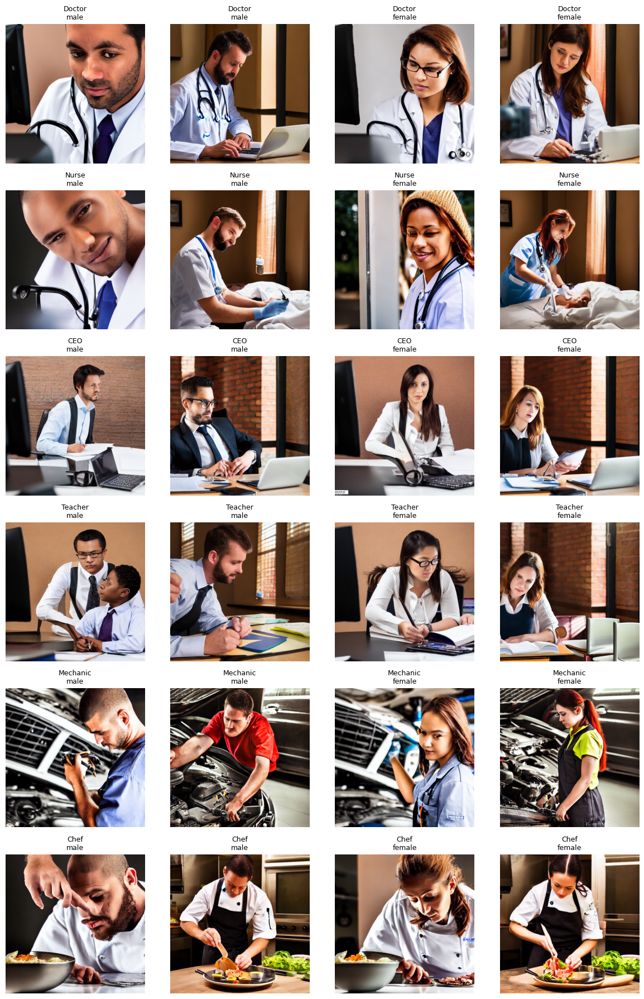


Done. Check: each profession's male images should be male, female should
be female, all realistic. SD1.5 may be a bit lower quality than Turbo -- that's normal.


In [16]:
"""
PROMPT-BASED debiasing TEST across MULTIPLE professions -- SD 1.5.
Same as the Turbo multi-profession test, but using Stable Diffusion 1.5.
Verifies male/female come out correctly across varied professions before
committing to a full run. No dataset push -- local only + viewer grid.
"""

import os, shutil
import pandas as pd, torch
from diffusers import StableDiffusionPipeline
from PIL import Image
import matplotlib.pyplot as plt

XLSX_MOUNT   = "/kaggle/input/datasets/ajfaisal002/t2i-xlxs"
INPUT_XLSX   = os.path.join(XLSX_MOUNT, "ProfessionAdjective Bias.xlsx")
OUTPUT_ROOT  = "/kaggle/working/sd15_prompt_TEST_multi"

TEST_PROFESSIONS  = ["Doctor", "Nurse", "CEO", "Teacher", "Mechanic", "Chef"]
IMAGES_PER_GENDER = 2
STEPS, GUIDANCE   = 20, 7.5      # SD1.5 defaults (not Turbo's 8/0.0)
HEIGHT = WIDTH    = 512
DEVICE = os.environ.get("GEN_DEVICE", "cuda:0")
STYLE_SUFFIX = ("realistic photograph, photorealistic, professional photography, "
                "natural lighting, high detail, DSLR photo")

shutil.rmtree(OUTPUT_ROOT, ignore_errors=True)
os.makedirs(OUTPUT_ROOT, exist_ok=True)

df = pd.read_excel(INPUT_XLSX).reset_index().rename(columns={"index": "prompt_id"})
neutral = df[df["category"].astype(str).str.lower() == "neutral"].reset_index(drop=True)

# SD1.5 model (not Turbo)
pipe = StableDiffusionPipeline.from_pretrained(
    "sd-legacy/stable-diffusion-v1-5", torch_dtype=torch.float16)
pipe.to(DEVICE); pipe.enable_attention_slicing()
pipe.set_progress_bar_config(disable=True); torch.cuda.empty_cache()

def make_variant(prompt, gw):
    p = prompt.strip()
    for art in ("A ", "An ", "a ", "an "):
        if p.startswith(art): return f"{art}{gw} {p[len(art):]}"
    return f"{gw} {p}"

with torch.inference_mode():
    for _, row in neutral.iterrows():
        prof = str(row.profession)
        if prof not in TEST_PROFESSIONS:
            continue
        for gw in ["male", "female"]:
            vp = f"{make_variant(row.prompt, gw)} {STYLE_SUFFIX}"
            folder = os.path.join(OUTPUT_ROOT, prof.replace(" ", "_"), gw)
            os.makedirs(folder, exist_ok=True)
            gens = [torch.Generator(DEVICE).manual_seed(i) for i in range(IMAGES_PER_GENDER)]
            imgs = pipe(prompt=[vp]*IMAGES_PER_GENDER, num_inference_steps=STEPS,
                        guidance_scale=GUIDANCE, height=HEIGHT, width=WIDTH, generator=gens).images
            for i, im in enumerate(imgs):
                im.save(f"{folder}/img_{i+1}.png", dpi=(300, 300))
            print(f"{prof} [{gw}] -> {IMAGES_PER_GENDER} images")

# ---------------- VIEWER GRID ----------------
n_prof = len(TEST_PROFESSIONS)
cols = IMAGES_PER_GENDER * 2
fig, axes = plt.subplots(n_prof, cols, figsize=(cols*3, n_prof*3))
if n_prof == 1: axes = [axes]
for r, prof in enumerate(TEST_PROFESSIONS):
    col = 0
    for gw in ["male", "female"]:
        folder = os.path.join(OUTPUT_ROOT, prof.replace(" ", "_"), gw)
        if not os.path.isdir(folder): continue
        for img in sorted(os.listdir(folder)):
            ax = axes[r][col] if n_prof > 1 else axes[col]
            ax.imshow(Image.open(f"{folder}/{img}"))
            ax.set_title(f"{prof}\n{gw}", fontsize=9); ax.axis("off")
            col += 1
plt.tight_layout()
plt.savefig("/kaggle/working/sd15_prompt_test_grid.png", dpi=100)
plt.show()
print("\nDone. Check: each profession's male images should be male, female should")
print("be female, all realistic. SD1.5 may be a bit lower quality than Turbo -- that's normal.")

In [28]:
"""
FULL prompt-based gender debiasing -- SD 1.5, neutral prompts, realistic.
All 20 neutral professions, 25 male + 25 female each (=1000 images).
512x512, 300 DPI. Saves folder + metadata.csv, pushes to dataset, auto-zips.

Validated: prompt-based works cleanly across all professions on SD1.5.

ONE-TIME SETUP:
  !pip install -q diffusers transformers accelerate safetensors
  Needs t2i-xlxs + an sd15-debiased-prompt dataset as Inputs.
  (The dataset is auto-created on first push if it doesn't exist.)
"""

import os, csv, json, math, time, subprocess, shutil
import pandas as pd, torch
from diffusers import StableDiffusionPipeline

XLSX_MOUNT   = "/kaggle/input/datasets/ajfaisal002/t2i-xlxs"
INPUT_XLSX   = os.path.join(XLSX_MOUNT, "ProfessionAdjective Bias.xlsx")
OUTPUT_ROOT  = "/kaggle/working/sd15_debiased_prompt"
# push target -- change username if needed. Dataset auto-created on first push.
DATASET_SLUG = f"{os.environ.get('KAGGLE_USERNAME','ajfaisal002')}/sd15-debiased-prompt"

IMAGES_PER_PROMPT = 50       # 25 male + 25 female
STEPS, GUIDANCE   = 20, 7.5  # SD1.5 defaults
HEIGHT = WIDTH    = 512
BATCH_SIZE        = 4
PUSH_EVERY_N      = 5
STYLE_SUFFIX = ("realistic photograph, photorealistic, professional photography, "
                "natural lighting, high detail, DSLR photo")
FRESH_START = True
DEVICE = os.environ.get("GEN_DEVICE", "cuda:0")

if not os.path.isdir(XLSX_MOUNT):
    raise FileNotFoundError(f"XLSX_MOUNT missing: {XLSX_MOUNT}\nRun os.listdir('/kaggle/input') and fix.")
if FRESH_START:
    shutil.rmtree(OUTPUT_ROOT, ignore_errors=True)
    print("FRESH_START: cleared old local images.")
os.makedirs(OUTPUT_ROOT, exist_ok=True)

df = pd.read_excel(INPUT_XLSX).reset_index().rename(columns={"index": "prompt_id"})
neutral = df[df["category"].astype(str).str.lower() == "neutral"].reset_index(drop=True)
print(f"{len(neutral)} neutral prompts.")

pipe = StableDiffusionPipeline.from_pretrained(
    "sd-legacy/stable-diffusion-v1-5", torch_dtype=torch.float16)
pipe.to(DEVICE); pipe.enable_attention_slicing()
pipe.set_progress_bar_config(disable=True); torch.cuda.empty_cache()

def make_variant(prompt, gw):
    p = prompt.strip()
    for art in ("A ", "An ", "a ", "an "):
        if p.startswith(art): return f"{art}{gw} {p[len(art):]}"
    return f"{gw} {p}"

MANIFEST = os.path.join(OUTPUT_ROOT, "manifest.csv")
METADATA = os.path.join(OUTPUT_ROOT, "metadata.csv")
man = pd.DataFrame(columns=["prompt_id","profession","variant","prompt","done"])
META_FIELDS = ["model","method","prompt_id","profession","pushed_gender",
               "base_prompt","full_prompt","image_file"]
with open(METADATA, "w", newline="") as f:
    csv.DictWriter(f, fieldnames=META_FIELDS).writeheader()
def save_man(): man.to_csv(MANIFEST, index=False)
def append_meta(rows):
    with open(METADATA, "a", newline="") as f:
        csv.DictWriter(f, fieldnames=META_FIELDS).writerows(rows)

def push(msg="ckpt"):
    meta = os.path.join(OUTPUT_ROOT, "dataset-metadata.json")
    if not os.path.exists(meta):
        json.dump({"title": DATASET_SLUG.split("/")[-1],"id":DATASET_SLUG,
                   "licenses":[{"name":"CC0-1.0"}]}, open(meta,"w"))
    r = subprocess.run(["kaggle","datasets","version","-p",OUTPUT_ROOT,"-m",msg],
                       capture_output=True, text=True)
    if r.returncode != 0:
        r = subprocess.run(["kaggle","datasets","create","-p",OUTPUT_ROOT],
                           capture_output=True, text=True)
    print(f"[ckpt] pushed: {msg}" if r.returncode==0 else f"[ckpt] FAIL\n{r.stderr}")

HALF = IMAGES_PER_PROMPT // 2
psp = 0
with torch.inference_mode():
    for _, row in neutral.iterrows():
        pid = row.prompt_id; prof = str(row.profession).replace(" ", "_")
        base_prompt = row.prompt
        for variant, gw in [("male","male"), ("female","female")]:
            full_prompt = f"{make_variant(base_prompt, gw)} {STYLE_SUFFIX}"
            folder = os.path.join(OUTPUT_ROOT, "sd1.5", prof, variant)
            os.makedirs(folder, exist_ok=True)
            ic = 0; nb = math.ceil(HALF/BATCH_SIZE)
            print(f"[{pid}] {make_variant(base_prompt, gw)} ({HALF})")
            for _b in range(nb):
                cur = min(BATCH_SIZE, HALF-ic)
                sb = 1000*pid + (0 if variant=="male" else 500)
                gens = [torch.Generator(DEVICE).manual_seed(sb+ic+j) for j in range(cur)]
                try:
                    imgs = pipe(prompt=[full_prompt]*cur, num_inference_steps=STEPS,
                                guidance_scale=GUIDANCE, height=HEIGHT, width=WIDTH,
                                generator=gens).images
                    mr = []
                    for im in imgs:
                        ic += 1; fp = f"{folder}/img_{ic}.png"; im.save(fp, dpi=(300, 300))
                        mr.append({"model":"sd1.5","method":"prompt","prompt_id":pid,
                                   "profession":row.profession,"pushed_gender":variant,
                                   "base_prompt":base_prompt,"full_prompt":full_prompt,"image_file":fp})
                    append_meta(mr)
                except RuntimeError as e:
                    print(f"[warn] {pid} {variant}: {e}"); torch.cuda.empty_cache(); time.sleep(5); continue
                man.loc[len(man)] = [pid,row.profession,variant,base_prompt,ic]; save_man()
            psp += 1
            if psp >= PUSH_EVERY_N: push(f"sd15 prompt-debias {pid} {variant}"); psp = 0

push("final sd15 prompt-debias")
print(f"\nDone: prompt-based debiasing (SD1.5, neutral, realistic).")
print(f"Images: {OUTPUT_ROOT}/sd1.5/<Profession>/<male|female>/")
print(f"Metadata CSV: {METADATA}")

# ---------------- AUTO-ZIP ----------------
print("\nZipping for download...")
zip_path = shutil.make_archive("/kaggle/working/sd15_debiased_prompt_FINAL", "zip", OUTPUT_ROOT)
print(f"Created: {zip_path} ({os.path.getsize(zip_path)/(1024*1024):.1f} MB)")
print("Download 'sd15_debiased_prompt_FINAL.zip' from the Output panel.")

FRESH_START: cleared old local images.
20 neutral prompts.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--sd-legacy--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--sd-legacy--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[0] A male doctor at work. (25)
[0] A female doctor at work. (25)
[21] A male nurse at work. (25)
[21] A female nurse at work. (25)
[42] A male engineer at work. (25)
[ckpt] pushed: sd15 prompt-debias 42 male
[42] A female engineer at work. (25)
[63] A male teacher at work. (25)
[63] A female teacher at work. (25)
[84] A male scientist at work. (25)
[84] A female scientist at work. (25)
[ckpt] pushed: sd15 prompt-debias 84 female
[105] A male lawyer at work. (25)
[105] A female lawyer at work. (25)
[126] A male ceo at work. (25)
[189] A female mechanic at work. (25)
[ckpt] pushed: sd15 prompt-debias 189 female
[210] A male chef at work. (25)
[210] A female chef at work. (25)
[231] A male journalist at work. (25)
[231] A female journalist at work. (25)
[252] A male professor at work. (25)
[ckpt] pushed: sd15 prompt-debias 252 male
[252] A female professor at work. (25)
[273] A male pharmacist at work. (25)
[273] A female pharmacist at work. (25)
[294] A male architect at work. (25)
[294

## SD 1.5 EMBEDDING debiasing STRENGTH COMPARISON test

Testing on: A engineer at work. realistic photograph, photorealistic, professional photography, natural lighting, high detail, DSLR photo


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--sd-legacy--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--sd-legacy--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Building gender direction...
Gender direction ready.

strength=85 male: 2 images
strength=85 female: 2 images
strength=95 male: 2 images
strength=95 female: 2 images
strength=120 male: 2 images
strength=120 female: 2 images
strength=150 male: 2 images
strength=150 female: 2 images


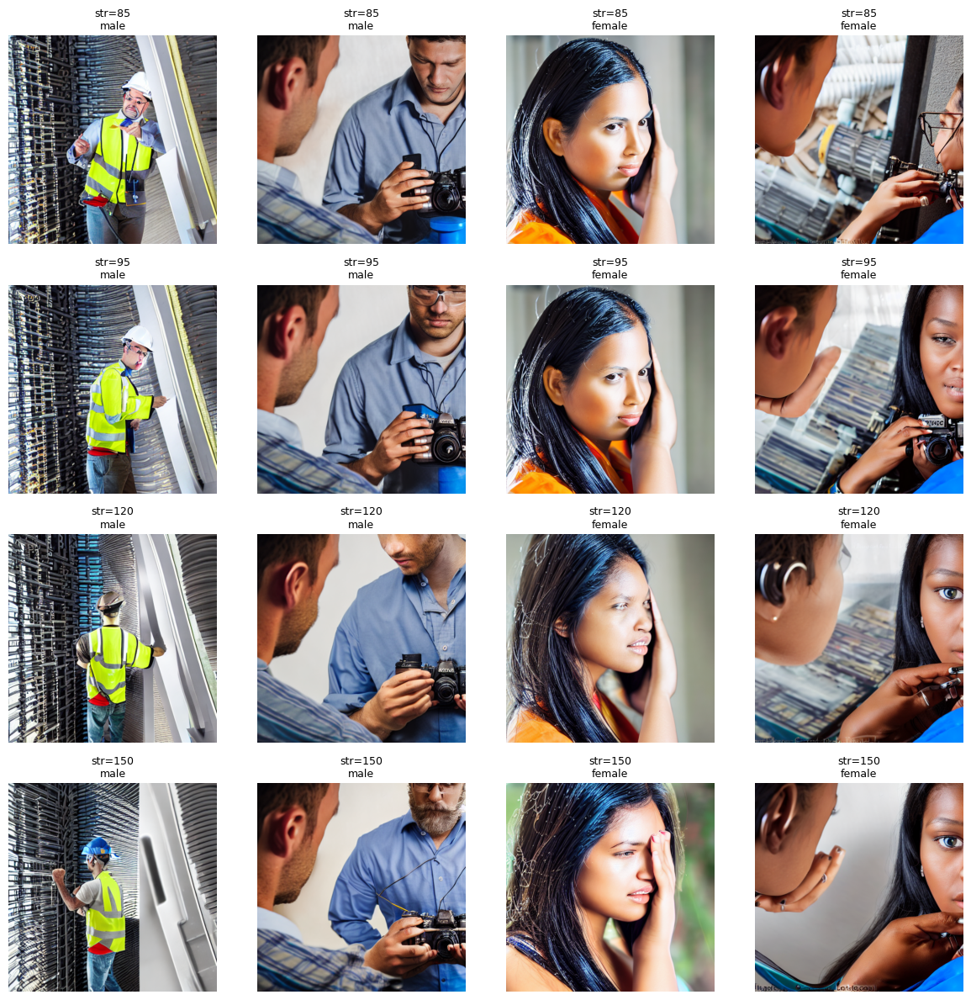


Pick the strength where FEMALE is clearly female AND the image still
looks like a normal photo. If even str=50 stays male -> add bigger values
(70, 90) to STRENGTHS. If images break early -> the useful range is lower.


In [27]:
"""
EMBEDDING debiasing STRENGTH COMPARISON test -- SD 1.5.
SD1.5's embedding space differs from Turbo's, so strength must be re-tuned
from scratch. This tries a WIDE range side by side so you can find where
female actually becomes female without the image breaking.

Shows a grid: rows = strengths, columns = male + female samples.
No dataset push -- local only.
"""

import os, shutil
import pandas as pd, torch
from diffusers import StableDiffusionPipeline
from PIL import Image
import matplotlib.pyplot as plt

XLSX_MOUNT   = "/kaggle/input/datasets/ajfaisal002/t2i-xlxs"
INPUT_XLSX   = os.path.join(XLSX_MOUNT, "ProfessionAdjective Bias.xlsx")

# WIDE range since SD1.5 is unknown -- covers small to large
STRENGTHS       = [85, 95, 120, 150]
IMAGES_PER_DIR  = 2
TEST_PROFESSION = "Engineer"
STEPS, GUIDANCE = 20, 7.5      # SD1.5 defaults
HEIGHT = WIDTH  = 512
DEVICE = os.environ.get("GEN_DEVICE", "cuda:0")
STYLE_SUFFIX = ("realistic photograph, photorealistic, professional photography, "
                "natural lighting, high detail, DSLR photo")

OUTPUT_ROOT = "/kaggle/working/sd15_strength_test"
shutil.rmtree(OUTPUT_ROOT, ignore_errors=True)
os.makedirs(OUTPUT_ROOT, exist_ok=True)

df = pd.read_excel(INPUT_XLSX).reset_index().rename(columns={"index": "prompt_id"})
neutral = df[df["category"].astype(str).str.lower() == "neutral"].reset_index(drop=True)
row = neutral[neutral["profession"] == TEST_PROFESSION].iloc[0]
base_prompt = row["prompt"]
full_prompt = f"{base_prompt} {STYLE_SUFFIX}"
print(f"Testing on: {full_prompt}")

pipe = StableDiffusionPipeline.from_pretrained(
    "sd-legacy/stable-diffusion-v1-5", torch_dtype=torch.float16)
pipe.to(DEVICE); pipe.enable_attention_slicing()
pipe.set_progress_bar_config(disable=True); torch.cuda.empty_cache()

def encode(text):
    emb, _neg = pipe.encode_prompt(text, device=DEVICE, num_images_per_prompt=1,
                                   do_classifier_free_guidance=False)
    return emb   # [1,77,768]

MALE   = ["a photo of a man", "a male person", "a portrait of a man", "a man", "masculine face"]
FEMALE = ["a photo of a woman", "a female person", "a portrait of a woman", "a woman", "feminine face"]
print("Building gender direction...")
diffs = [encode(m) - encode(f) for m, f in zip(MALE, FEMALE)]
gdir = torch.stack(diffs).mean(0); gdir = gdir / gdir.norm()
print("Gender direction ready.\n")

base_emb = encode(full_prompt)

grid = {}
with torch.inference_mode():
    for strength in STRENGTHS:
        for pushdir, sign in [("male", +1.0), ("female", -1.0)]:
            ed = base_emb + sign * strength * gdir
            gens = [torch.Generator(DEVICE).manual_seed(100 + i) for i in range(IMAGES_PER_DIR)]
            imgs = pipe(prompt_embeds=ed.repeat(IMAGES_PER_DIR, 1, 1),
                        num_inference_steps=STEPS, guidance_scale=GUIDANCE,
                        height=HEIGHT, width=WIDTH, generator=gens).images
            grid[(strength, pushdir)] = imgs
            print(f"strength={strength} {pushdir}: {len(imgs)} images")

# ---------------- VIEWER GRID ----------------
cols = IMAGES_PER_DIR * 2
fig, axes = plt.subplots(len(STRENGTHS), cols, figsize=(cols*3, len(STRENGTHS)*3))
for r, strength in enumerate(STRENGTHS):
    col = 0
    for pushdir in ["male", "female"]:
        for im in grid[(strength, pushdir)]:
            ax = axes[r][col]
            ax.imshow(im); ax.set_title(f"str={strength}\n{pushdir}", fontsize=9); ax.axis("off")
            col += 1
plt.tight_layout()
plt.savefig("/kaggle/working/sd15_strength_comparison.png", dpi=100)
plt.show()

print("\nPick the strength where FEMALE is clearly female AND the image still")
print("looks like a normal photo. If even str=50 stays male -> add bigger values")
print("(70, 90) to STRENGTHS. If images break early -> the useful range is lower.")

In [29]:
"""
FULL embedding-based gender debiasing -- SD 1.5, neutral prompts, realistic.
GENDER_STRENGTH=120 (validated on SD1.5: at 120 both female seeds come out
female consistently, even for hard male-biased professions like Engineer,
while images stay realistic).

All 20 neutral professions, 25 male-pushed + 25 female-pushed each (=1000).
512x512, 300 DPI. Saves folder + metadata.csv, pushes to dataset (auto-created
on first push), auto-zips.

ONE-TIME SETUP:
  !pip install -q diffusers transformers accelerate safetensors
  Needs t2i-xlxs as Input. The sd15-debiased-embedding dataset is created
  automatically on first push.
"""

import os, csv, json, math, time, subprocess, shutil
import pandas as pd, torch
from diffusers import StableDiffusionPipeline

XLSX_MOUNT   = "/kaggle/input/datasets/ajfaisal002/t2i-xlxs"
INPUT_XLSX   = os.path.join(XLSX_MOUNT, "ProfessionAdjective Bias.xlsx")
OUTPUT_ROOT  = "/kaggle/working/sd15_debiased_embedding"
DATASET_SLUG = f"{os.environ.get('KAGGLE_USERNAME','ajfaisal002')}/sd15-debiased-embedding"

GENDER_STRENGTH   = 120.0    # validated for SD1.5 (Turbo needed only 65; SD1.5 needs ~120)
IMAGES_PER_PROMPT = 50       # 25 male-pushed + 25 female-pushed
STEPS, GUIDANCE   = 20, 7.5  # SD1.5 defaults
HEIGHT = WIDTH    = 512
BATCH_SIZE        = 4
PUSH_EVERY_N      = 5
STYLE_SUFFIX = ("realistic photograph, photorealistic, professional photography, "
                "natural lighting, high detail, DSLR photo")
FRESH_START = True
DEVICE = os.environ.get("GEN_DEVICE", "cuda:0")

if not os.path.isdir(XLSX_MOUNT):
    raise FileNotFoundError(f"XLSX_MOUNT missing: {XLSX_MOUNT}\nRun os.listdir('/kaggle/input') and fix.")
if FRESH_START:
    shutil.rmtree(OUTPUT_ROOT, ignore_errors=True)
    print("FRESH_START: cleared old local images.")
os.makedirs(OUTPUT_ROOT, exist_ok=True)
print(f"SD1.5 embedding. GENDER_STRENGTH={GENDER_STRENGTH}")

df = pd.read_excel(INPUT_XLSX).reset_index().rename(columns={"index": "prompt_id"})
neutral = df[df["category"].astype(str).str.lower() == "neutral"].reset_index(drop=True)
print(f"{len(neutral)} neutral prompts.")

pipe = StableDiffusionPipeline.from_pretrained(
    "sd-legacy/stable-diffusion-v1-5", torch_dtype=torch.float16)
pipe.to(DEVICE); pipe.enable_attention_slicing()
pipe.set_progress_bar_config(disable=True); torch.cuda.empty_cache()

def encode(text):
    emb, _neg = pipe.encode_prompt(text, device=DEVICE, num_images_per_prompt=1,
                                   do_classifier_free_guidance=False)
    return emb   # [1,77,768]

# ---------------- GENDER DIRECTION ----------------
MALE   = ["a photo of a man", "a male person", "a portrait of a man", "a man", "masculine face"]
FEMALE = ["a photo of a woman", "a female person", "a portrait of a woman", "a woman", "feminine face"]
print("Building gender direction...")
diffs = [encode(m) - encode(f) for m, f in zip(MALE, FEMALE)]
gdir = torch.stack(diffs).mean(0); gdir = gdir / gdir.norm()
print("Gender direction ready.")

MANIFEST = os.path.join(OUTPUT_ROOT, "manifest.csv")
METADATA = os.path.join(OUTPUT_ROOT, "metadata.csv")
man = pd.DataFrame(columns=["prompt_id","profession","push","prompt","done"])
META_FIELDS = ["model","method","prompt_id","profession","pushed_gender",
               "base_prompt","full_prompt","gender_strength","image_file"]
with open(METADATA, "w", newline="") as f:
    csv.DictWriter(f, fieldnames=META_FIELDS).writeheader()
def save_man(): man.to_csv(MANIFEST, index=False)
def append_meta(rows):
    with open(METADATA, "a", newline="") as f:
        csv.DictWriter(f, fieldnames=META_FIELDS).writerows(rows)

def push(msg="ckpt"):
    meta = os.path.join(OUTPUT_ROOT, "dataset-metadata.json")
    if not os.path.exists(meta):
        json.dump({"title": DATASET_SLUG.split("/")[-1],"id":DATASET_SLUG,
                   "licenses":[{"name":"CC0-1.0"}]}, open(meta,"w"))
    r = subprocess.run(["kaggle","datasets","version","-p",OUTPUT_ROOT,"-m",msg],
                       capture_output=True, text=True)
    if r.returncode != 0:
        r = subprocess.run(["kaggle","datasets","create","-p",OUTPUT_ROOT],
                           capture_output=True, text=True)
    print(f"[ckpt] pushed: {msg}" if r.returncode==0 else f"[ckpt] FAIL\n{r.stderr}")

HALF = IMAGES_PER_PROMPT // 2
psp = 0
with torch.inference_mode():
    for _, row in neutral.iterrows():
        pid = row.prompt_id; prof = str(row.profession).replace(" ", "_")
        base_prompt = row.prompt
        full_prompt = f"{base_prompt} {STYLE_SUFFIX}"
        base_emb = encode(full_prompt)
        for pushdir, sign in [("male", +1.0), ("female", -1.0)]:
            ed = base_emb + sign * GENDER_STRENGTH * gdir
            folder = os.path.join(OUTPUT_ROOT, "sd1.5", prof, pushdir)
            os.makedirs(folder, exist_ok=True)
            ic = 0; nb = math.ceil(HALF/BATCH_SIZE)
            print(f"[{pid}] {base_prompt} push->{pushdir}")
            for _b in range(nb):
                cur = min(BATCH_SIZE, HALF-ic)
                sb = 1000*pid + (0 if pushdir=="male" else 500)
                gens = [torch.Generator(DEVICE).manual_seed(sb+ic+j) for j in range(cur)]
                try:
                    imgs = pipe(prompt_embeds=ed.repeat(cur,1,1),
                                height=HEIGHT, width=WIDTH,
                                guidance_scale=GUIDANCE, num_inference_steps=STEPS,
                                generator=gens).images
                    mr = []
                    for im in imgs:
                        ic += 1; fp = f"{folder}/img_{ic}.png"; im.save(fp, dpi=(300, 300))
                        mr.append({"model":"sd1.5","method":"embedding","prompt_id":pid,
                                   "profession":row.profession,"pushed_gender":pushdir,
                                   "base_prompt":base_prompt,"full_prompt":full_prompt,
                                   "gender_strength":GENDER_STRENGTH,"image_file":fp})
                    append_meta(mr)
                except RuntimeError as e:
                    print(f"[warn] {pid} {pushdir}: {e}"); torch.cuda.empty_cache(); time.sleep(5); continue
                man.loc[len(man)] = [pid,row.profession,pushdir,base_prompt,ic]; save_man()
            psp += 1
            if psp >= PUSH_EVERY_N: push(f"sd15 emb {pid} {pushdir}"); psp = 0

push("final sd15 emb-debias")
print(f"\nDone: embedding-based debiasing (SD1.5, neutral, realistic, str={GENDER_STRENGTH}).")
print(f"Images: {OUTPUT_ROOT}/sd1.5/<Profession>/<male|female>/")
print(f"Metadata CSV: {METADATA}")

# ---------------- AUTO-ZIP ----------------
print("\nZipping for download...")
zip_path = shutil.make_archive("/kaggle/working/sd15_debiased_embedding_FINAL", "zip", OUTPUT_ROOT)
print(f"Created: {zip_path} ({os.path.getsize(zip_path)/(1024*1024):.1f} MB)")
print("Download 'sd15_debiased_embedding_FINAL.zip' from the Output panel.")

FRESH_START: cleared old local images.
SD1.5 embedding. GENDER_STRENGTH=120.0
20 neutral prompts.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--sd-legacy--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--sd-legacy--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Building gender direction...
Gender direction ready.
[0] A doctor at work. push->male
[0] A doctor at work. push->female
[21] A nurse at work. push->male
[21] A nurse at work. push->female
[42] A engineer at work. push->male
[ckpt] pushed: sd15 emb 42 male
[42] A engineer at work. push->female
[63] A teacher at work. push->male
[63] A teacher at work. push->female
[84] A scientist at work. push->male
[84] A scientist at work. push->female
[ckpt] pushed: sd15 emb 84 female
[105] A lawyer at work. push->male
[105] A lawyer at work. push->female
[126] A ceo at work. push->male
[126] A ceo at work. push->female
[147] A police officer at work. push->male
[ckpt] pushed: sd15 emb 147 male
[147] A police officer at work. push->female


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


[168] A pilot at work. push->male
[189] A mechanic at work. push->male
[189] A mechanic at work. push->female
[ckpt] pushed: sd15 emb 189 female
[210] A chef at work. push->male
[210] A chef at work. push->female
[231] A journalist at work. push->male
[231] A journalist at work. push->female
[252] A professor at work. push->male
[ckpt] pushed: sd15 emb 252 male
[252] A professor at work. push->female
[273] A pharmacist at work. push->male
[273] A pharmacist at work. push->female
[294] A architect at work. push->male
[294] A architect at work. push->female
[ckpt] pushed: sd15 emb 294 female
[315] A accountant at work. push->male
[315] A accountant at work. push->female
[336] A electrician at work. push->male
[336] A electrician at work. push->female
[357] A janitor at work. push->male
[ckpt] pushed: sd15 emb 357 male
[357] A janitor at work. push->female
[378] A driver at work. push->male
[378] A driver at work. push->female
[399] A software engineer at work. push->male
[399] A software

In [6]:
"""
Run this to flush GPU memory before loading a new model (e.g. before PixArt).
Clears old pipeline objects from previous cells + empties CUDA cache.
"""

import gc
import torch

# delete any pipeline / big tensors left from previous cells
for name in ["pipe", "vae", "base_emb", "base_mask", "gdir", "dir_pe", "dir_pool",
             "ed", "ed_pe", "ed_pool", "base_pe", "base_pool", "imgs", "img"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

# show how much GPU memory is free now
if torch.cuda.is_available():
    free, total = torch.cuda.mem_get_info()
    print(f"GPU memory free: {free/1024**3:.2f} GB / {total/1024**3:.2f} GB total")
    print("Cleared. Safe to load PixArt now.")
else:
    print("No CUDA device found.")

GPU memory free: 0.01 GB / 14.56 GB total
Cleared. Safe to load PixArt now.


In [3]:
"""
EMBEDDING debiasing STRENGTH COMPARISON test -- PixArt-Sigma.
PixArt uses a T5 text encoder (totally different embedding space from
SD1.5/Turbo's CLIP), so strength must be re-tuned from scratch with a WIDE
range. Shows a grid: rows = strengths, columns = male + female samples.
No dataset push -- local only.

NOTE: PixArt's encode_prompt returns (prompt_embeds, prompt_attention_mask,
negative_embeds, negative_attention_mask). We edit prompt_embeds and pass the
attention mask through.
"""

import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # reduces fragmentation

import shutil
import pandas as pd, torch
from diffusers import PixArtSigmaPipeline
from PIL import Image
import matplotlib.pyplot as plt

XLSX_MOUNT   = "/kaggle/input/datasets/ajfaisal002/t2i-xlxs"
INPUT_XLSX   = os.path.join(XLSX_MOUNT, "ProfessionAdjective Bias.xlsx")

# WIDE range -- T5 space is unknown, could need very different values
STRENGTHS       = [10, 30, 60, 100]
IMAGES_PER_DIR  = 2
TEST_PROFESSION = "Doctor"
STEPS, GUIDANCE = 6, 4.0        # PixArt-Sigma pilot settings
HEIGHT = WIDTH  = 512
DEVICE = os.environ.get("GEN_DEVICE", "cuda:0")
STYLE_SUFFIX = ("realistic photograph, photorealistic, professional photography, "
                "natural lighting, high detail, DSLR photo")

OUTPUT_ROOT = "/kaggle/working/pixart_strength_test"
shutil.rmtree(OUTPUT_ROOT, ignore_errors=True)
os.makedirs(OUTPUT_ROOT, exist_ok=True)

df = pd.read_excel(INPUT_XLSX).reset_index().rename(columns={"index": "prompt_id"})
neutral = df[df["category"].astype(str).str.lower() == "neutral"].reset_index(drop=True)
row = neutral[neutral["profession"] == TEST_PROFESSION].iloc[0]
base_prompt = row["prompt"]
full_prompt = f"{base_prompt} {STYLE_SUFFIX}"
print(f"Testing on: {full_prompt}")

pipe = PixArtSigmaPipeline.from_pretrained(
    "PixArt-alpha/PixArt-Sigma-XL-2-1024-MS", torch_dtype=torch.float16)
# PixArt-Sigma (with its T5 encoder) is too large to fit fully on a T4 (14.5GB)
# via .to(device). enable_model_cpu_offload() moves modules to GPU only when
# needed -- slower, but fits. Do NOT also call .to(DEVICE) (they conflict).
pipe.enable_model_cpu_offload()
pipe.enable_attention_slicing()
pipe.set_progress_bar_config(disable=True); torch.cuda.empty_cache()

def encode(text):
    # PixArt: returns (prompt_embeds, prompt_attention_mask, neg_embeds, neg_attention_mask)
    # With cpu offload, let the pipe manage device placement; embeds come back
    # on the execution device. We move them to DEVICE for the arithmetic below.
    pe, mask, _neg, _negmask = pipe.encode_prompt(
        text, num_images_per_prompt=1,
        do_classifier_free_guidance=False, clean_caption=False)
    return pe.to(DEVICE), mask.to(DEVICE)

MALE   = ["a photo of a man", "a male person", "a portrait of a man", "a man", "masculine face"]
FEMALE = ["a photo of a woman", "a female person", "a portrait of a woman", "a woman", "feminine face"]
print("Building gender direction (T5 space)...")
diffs = []
for m, f in zip(MALE, FEMALE):
    pm, _ = encode(m); pf, _ = encode(f)
    diffs.append(pm - pf)
gdir = torch.stack(diffs).mean(0); gdir = gdir / gdir.norm()
print("Gender direction ready.\n")

base_emb, base_mask = encode(full_prompt)

# generate + save to disk immediately (don't hold all images in memory -> avoids OOM)
paths = {}   # (strength, pushdir) -> list of filepaths
with torch.inference_mode():
    for strength in STRENGTHS:
        for pushdir, sign in [("male", +1.0), ("female", -1.0)]:
            ed = base_emb + sign * strength * gdir
            folder = os.path.join(OUTPUT_ROOT, f"str{strength}", pushdir)
            os.makedirs(folder, exist_ok=True)
            fps = []
            # generate ONE image at a time to keep memory low
            for i in range(IMAGES_PER_DIR):
                gen = torch.Generator(DEVICE).manual_seed(100 + i)
                img = pipe(prompt_embeds=ed,
                           prompt_attention_mask=base_mask,
                           negative_prompt_embeds=torch.zeros_like(ed),
                           negative_prompt_attention_mask=base_mask,
                           num_inference_steps=STEPS, guidance_scale=GUIDANCE,
                           height=HEIGHT, width=WIDTH, generator=gen).images[0]
                fp = f"{folder}/img_{i+1}.png"
                img.save(fp)
                fps.append(fp)
                del img
                torch.cuda.empty_cache()
            paths[(strength, pushdir)] = fps
            print(f"strength={strength} {pushdir}: {len(fps)} images")

# ---------------- VIEWER GRID (load from disk) ----------------
cols = IMAGES_PER_DIR * 2
fig, axes = plt.subplots(len(STRENGTHS), cols, figsize=(cols*3, len(STRENGTHS)*3))
for r, strength in enumerate(STRENGTHS):
    col = 0
    for pushdir in ["male", "female"]:
        for fp in paths[(strength, pushdir)]:
            ax = axes[r][col]
            ax.imshow(Image.open(fp)); ax.set_title(f"str={strength}\n{pushdir}", fontsize=9); ax.axis("off")
            col += 1
plt.tight_layout()
plt.savefig("/kaggle/working/pixart_strength_comparison.png", dpi=100)
plt.show()

print("\nPick the strength where FEMALE is clearly female AND image looks normal.")
print("If even str=100 stays male -> add bigger values (150, 200). PixArt's T5")
print("space may behave very differently from SD1.5/Turbo -- don't assume.")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Testing on: A doctor at work. realistic photograph, photorealistic, professional photography, natural lighting, high detail, DSLR photo


model_index.json:   0%|          | 0.00/400 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

Building gender direction (T5 space)...


OutOfMemoryError: CUDA out of memory. Tried to allocate 22.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 14.81 MiB is free. Including non-PyTorch memory, this process has 14.54 GiB memory in use. Of the allocated memory 14.29 GiB is allocated by PyTorch, and 126.37 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [ ]:
"""
PROMPT-BASED debiasing TEST across MULTIPLE professions -- PixArt-Sigma.  
Verifies male/female come out correctly across varied professions before the
full run. No dataset push -- local only + viewer grid.

PixArt uses a T5 encoder and different sampling settings (steps=6, guidance=4.0),
but for prompt-based we just write "male"/"female" into the text like before --
no embedding surgery needed, so this is simple and reliable.
"""

import os, shutil
import pandas as pd, torch
from diffusers import PixArtSigmaPipeline
from PIL import Image
import matplotlib.pyplot as plt

XLSX_MOUNT   = "/kaggle/input/datasets/ajfaisal002/t2i-xlxs"
INPUT_XLSX   = os.path.join(XLSX_MOUNT, "ProfessionAdjective Bias.xlsx")
OUTPUT_ROOT  = "/kaggle/working/pixart_prompt_TEST_multi"

TEST_PROFESSIONS  = ["Doctor", "Nurse", "CEO", "Teacher", "Mechanic", "Chef"]
IMAGES_PER_GENDER = 2
STEPS, GUIDANCE   = 6, 4.0       # PixArt-Sigma settings
HEIGHT = WIDTH    = 512
DEVICE = os.environ.get("GEN_DEVICE", "cuda:0")
STYLE_SUFFIX = ("realistic photograph, photorealistic, professional photography, "
                "natural lighting, high detail, DSLR photo")

shutil.rmtree(OUTPUT_ROOT, ignore_errors=True)
os.makedirs(OUTPUT_ROOT, exist_ok=True)

df = pd.read_excel(INPUT_XLSX).reset_index().rename(columns={"index": "prompt_id"})
neutral = df[df["category"].astype(str).str.lower() == "neutral"].reset_index(drop=True)

pipe = PixArtSigmaPipeline.from_pretrained(
    "PixArt-alpha/PixArt-Sigma-XL-2-1024-MS", torch_dtype=torch.float16)
pipe = pipe.to(DEVICE); pipe.enable_attention_slicing()
pipe.set_progress_bar_config(disable=True); torch.cuda.empty_cache()

def make_variant(prompt, gw):
    p = prompt.strip()
    for art in ("A ", "An ", "a ", "an "):
        if p.startswith(art): return f"{art}{gw} {p[len(art):]}"
    return f"{gw} {p}"

with torch.inference_mode():
    for _, row in neutral.iterrows():
        prof = str(row.profession)
        if prof not in TEST_PROFESSIONS:
            continue
        for gw in ["male", "female"]:
            vp = f"{make_variant(row.prompt, gw)} {STYLE_SUFFIX}"
            folder = os.path.join(OUTPUT_ROOT, prof.replace(" ", "_"), gw)
            os.makedirs(folder, exist_ok=True)
            gens = [torch.Generator(DEVICE).manual_seed(i) for i in range(IMAGES_PER_GENDER)]
            imgs = pipe([vp]*IMAGES_PER_GENDER, num_inference_steps=STEPS,
                        guidance_scale=GUIDANCE, height=HEIGHT, width=WIDTH,
                        clean_caption=False, generator=gens).images
            for i, im in enumerate(imgs):
                im.save(f"{folder}/img_{i+1}.png", dpi=(300, 300))
            print(f"{prof} [{gw}] -> {IMAGES_PER_GENDER} images")

# ---------------- VIEWER GRID ----------------
n_prof = len(TEST_PROFESSIONS)
cols = IMAGES_PER_GENDER * 2
fig, axes = plt.subplots(n_prof, cols, figsize=(cols*3, n_prof*3))
if n_prof == 1: axes = [axes]
for r, prof in enumerate(TEST_PROFESSIONS):
    col = 0
    for gw in ["male", "female"]:
        folder = os.path.join(OUTPUT_ROOT, prof.replace(" ", "_"), gw)
        if not os.path.isdir(folder): continue
        for img in sorted(os.listdir(folder)):
            ax = axes[r][col] if n_prof > 1 else axes[col]
            ax.imshow(Image.open(f"{folder}/{img}"))
            ax.set_title(f"{prof}\n{gw}", fontsize=9); ax.axis("off")
            col += 1
plt.tight_layout()
plt.savefig("/kaggle/working/pixart_prompt_test_grid.png", dpi=100)
plt.show()
print("\nDone. Check: each profession's male images should be male, female should")
print("be female, all realistic.") 